# How many KBMs does a fixed WIDTH and NBASIS get right? (TGLF and GFTM)

Five plots per code, each drawn for several error tolerances $x$. All use only the simulations themselves.

1. **Extent within $x$ of GS2.** At each fixed WIDTH and NBASIS, the fraction of the 738 GS2-KBMs for which the code's
   95 % extent is within $x$ of GS2's, $\lvert\theta_{\rm code}/\theta_{\rm GS2}-1\rvert\le x$: three versions, for $\phi$ only,
   $A_\parallel$ only, and both fields at once.
2. **Growth rate within $x$ of the highest NBASIS.** The fraction for which the code's $\gamma$ is within $x$ of the same code's
   $\gamma$ at its highest NBASIS and the same WIDTH: $\lvert\gamma_N/\gamma_{N_{\rm top}}-1\rvert\le x$. This measures
   convergence in NBASIS, not agreement with GS2.
3. **Growth rate within $x$ of GS2.** The fraction for which $\lvert\gamma_{\rm code}/\gamma_{\rm GS2}-1\rvert\le x$.

Both are fractions of all 738 samples. A sample counts as a failure when the code finds no KBM-like mode, i.e. no mode with
$\gamma>0$ and $\omega>0$ (ion direction). In plot 2 it also fails when the code finds none at the top NBASIS.

**Data**, all existing (nothing is run here):
- **GS2:** the `kbm_free` cubes.
- **Code runs:** the fixed-WIDTH leaves of `Fusion_PhD-qp5.37`/`qp5.40` (catalogue section "`kbm_free` fixed WIDTH × NBASIS").
  They were built only for the 738 GS2-KBMs (203 SPR-045, 140 M1, 208 R4, 187 R3), so they also define the population.
  - **TGLF:** SAT_RULE 2, FILTER $-1.5$, MHD rule off, $A_\parallel$ and $B_\parallel$ on, `FIND_WIDTH` F, NXGRID 32.
  - **GFTM:** stock, FILTER 0.5.
  - Every run has NXGRID $\ge$ NBASIS + 8.

In [1]:
import os
import re
from multiprocessing import get_context
from pathlib import Path
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, StrMethodFormatter
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "TGLF_GFTM_KBM_PAPER" / "basis_resolution_rule"   # the paper folder `make figures` copies from
plots_dir.mkdir(parents=True, exist_ok=True)

cases = ["SPR-045", "M1", "R4", "R3"]
widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6,
          1.9218, 2.3083, 2.7726, 3.3302, 4.0]
# (NBASIS, NXGRID) of every run used. TGLF's NXGRID cannot exceed 32, so its top NBASIS is 24; GFTM's NXGRID cannot exceed 65, so its top is 56.
cells = {"TGLF": [(2, 32), (4, 32), (6, 32), (8, 32), (12, 32), (16, 32), (24, 32)],
         "GFTM": [(2, 32), (4, 32), (8, 32), (12, 32), (16, 32), (24, 32), (32, 40), (48, 65), (56, 64)]}
tolerances = [0.05, 0.10, 0.20]          # the x of the plots; add or change values here
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))


def leaf_path(code, case, width, nbasis, nxgrid):
    width_tag = f"w{width:.4f}".replace(".", "p")
    if code == "TGLF":
        return data_root / "TGLF/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"fx_fm1p5_{width_tag}_nb{nbasis}"
    return data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{width_tag}_nb{nbasis}_nx{nxgrid}"


def extent_95(squared_field):
    # pyro's 95 % extent rule, sample by sample (Extent._compute is the function Extent(output) calls). Pyro's Extent(output)
    # cannot take GS2's theta grid, which is NaN outside each sample's own points, so the NaNs are dropped first.
    # A run with no output has an all-NaN field: its extent is NaN.
    return np.array([float(Extent._compute(row.dropna("theta").expand_dims("sample"), 0.95)[0][0]) if row.notnull().any() else np.nan
                     for row in squared_field.transpose("sample", "theta")])

## GS2 extents of the 738 KBMs

In [2]:
gs2_rows = []
for case in cases:
    leaf = data_root / "GS2/Runs/LATIN_HYPERCUBE" / case / "kbm_free"
    gs2_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    population = [str(name) for name in PyroHypercube(pyroscan_json=leaf_path("GFTM", case, 1.0, 16, 32) / "pyroscan.json", load_base_pyro=True).pyro_dict]   # the KBMs
    gs2_output = gs2_scan.gk_output.data.set_index(sample="sample_name").sel(sample=population)
    gs2_rows.append(pd.DataFrame(dict(case=case, sample=population,
                                      gamma_gs2=gs2_output.growth_rate.pint.dequantify().values.ravel(),
                                      gamma_units_gs2=re.sub(r"_pyroscan_base\d+", "", str(gs2_output.growth_rate.data.units)),
                                      phi_extent_gs2=extent_95(gs2_output.phi_squared.pint.dequantify().squeeze("kx")),
                                      apar_extent_gs2=extent_95(gs2_output.apar_squared.pint.dequantify().squeeze("kx")))))
gs2 = pd.concat(gs2_rows, ignore_index=True)
assert len(gs2) == 738, len(gs2)
gs2.groupby("case").size()

case
M1         140
R3         187
R4         208
SPR-045    203
dtype: int64

## Code runs: $\gamma$, $\omega$ and the two extents of the dominant mode, for every (code, case, WIDTH, NBASIS)
With `IBRANCH` $-1$ the codes return modes ordered by growth rate, so mode 0 is the dominant one (checked below on every leaf).

In [3]:
def load_leaf(spec):
    code, case, width, nbasis, nxgrid = spec
    scan = PyroHypercube(pyroscan_json=leaf_path(code, case, width, nbasis, nxgrid) / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf_path(code, case, width, nbasis, nxgrid) / "pyroscan.nc")
    output = scan.gk_output.data.set_index(sample="sample_name")
    growth_rate = output.growth_rate.pint.dequantify()
    assert (growth_rate.fillna(-np.inf).argmax("mode") == 0).all()
    dominant = output.isel(mode=0)  # mode0-guard-allow: IBRANCH -1, argmax == 0 asserted above
    return pd.DataFrame(dict(code=code, case=case, width=width, nbasis=nbasis, sample=[str(name) for name in output.sample.values],
                             gamma_units=re.sub(r"_pyroscan_base\d+", "", str(dominant.growth_rate.data.units)),
                             gamma=dominant.growth_rate.pint.dequantify().values,
                             omega=dominant.mode_frequency.pint.dequantify().values,
                             phi_extent=extent_95(abs(dominant.phi.pint.dequantify().squeeze("kx")) ** 2),
                             apar_extent=extent_95(abs(dominant.apar.pint.dequantify().squeeze("kx")) ** 2)))


specs = [(code, case, width, nbasis, nxgrid) for code in cells for case in cases for width in widths for nbasis, nxgrid in cells[code]]
with get_context("fork").Pool(n_cpu) as pool:     # about 1500 leaves; read in parallel
    runs = pd.concat(pool.map(load_leaf, specs, chunksize=4), ignore_index=True)
runs = runs.merge(gs2, on=["case", "sample"], validate="many_to_one")
assert (runs.groupby(["code", "width", "nbasis"]).size() == 738).all()
assert (runs.gamma_units == runs.gamma_units_gs2).all(), "code and GS2 growth rates are not in the same normalisation"
runs["found"] = (runs.gamma > 0) & (runs.omega > 0)      # a KBM-like mode: unstable, ion direction
runs.groupby(["code", "nbasis"]).found.mean().unstack(0).round(3)

code,GFTM,TGLF
nbasis,,
2,0.732,0.656
4,0.730,0.735
6,NaN,0.749
8,0.763,0.768
12,0.775,0.795
16,0.796,0.807
24,0.821,0.821
32,0.843,NaN
48,0.852,NaN


## The two quantities, per run
- `phi_extent_error`, `apar_extent_error`: $\lvert\theta^f_{\rm code}/\theta^f_{\rm GS2}-1\rvert$ for each field.
- `extent_error`: the larger of the two, so "within $x$" means both fields are.
- `gamma_change`: $\lvert\gamma_N/\gamma_{N_{\rm top}}-1\rvert$ against the same code, case, sample and WIDTH at the top NBASIS.
- `gamma_error_gs2`: $\lvert\gamma_{\rm code}/\gamma_{\rm GS2}-1\rvert$ (the code and GS2 normalisations are checked to be the same).

A run with no KBM-like mode gets an infinite error, so it is never "within". The top NBASIS itself is not drawn in plot 2
(it would be 1 by definition).

In [4]:
runs["phi_extent_error"] = abs(runs.phi_extent / runs.phi_extent_gs2 - 1)
runs["apar_extent_error"] = abs(runs.apar_extent / runs.apar_extent_gs2 - 1)
runs["extent_error"] = np.maximum(runs.phi_extent_error, runs.apar_extent_error)      # both fields within x
for column in ("phi_extent_error", "apar_extent_error", "extent_error"):
    runs.loc[~runs.found, column] = np.inf

top_nbasis = {code: max(nbasis for nbasis, _ in cells[code]) for code in cells}
top_runs = runs[runs.nbasis == runs.code.map(top_nbasis)][["code", "case", "sample", "width", "gamma", "found"]]
runs = runs.merge(top_runs, on=["code", "case", "sample", "width"], suffixes=("", "_top"), validate="many_to_one")
runs["gamma_change"] = abs(runs.gamma / runs.gamma_top - 1)
runs.loc[~(runs.found & runs.found_top), "gamma_change"] = np.inf
runs["gamma_error_gs2"] = abs(runs.gamma / runs.gamma_gs2 - 1)
runs.loc[~runs.found, "gamma_error_gs2"] = np.inf

## Plots
One figure per code, per quantity and per tolerance: x-axis WIDTH (log), y-axis the fraction of the 738 KBMs within the
tolerance, one line per NBASIS. The format is that of `basis_resolution_rule`'s `validation_fraction_vs_width_*` panels.

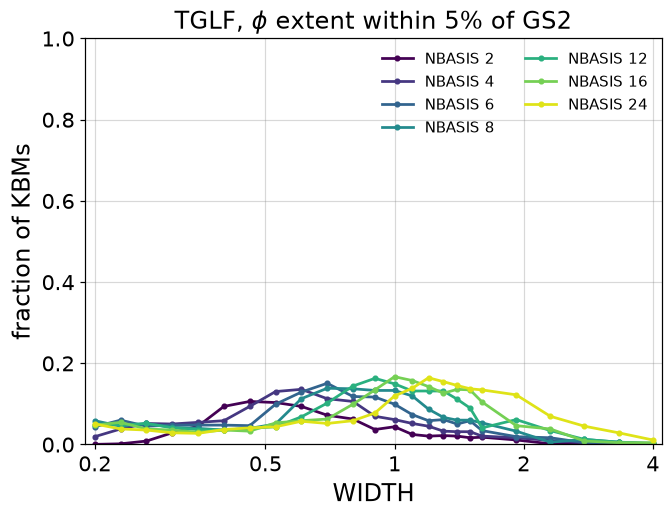

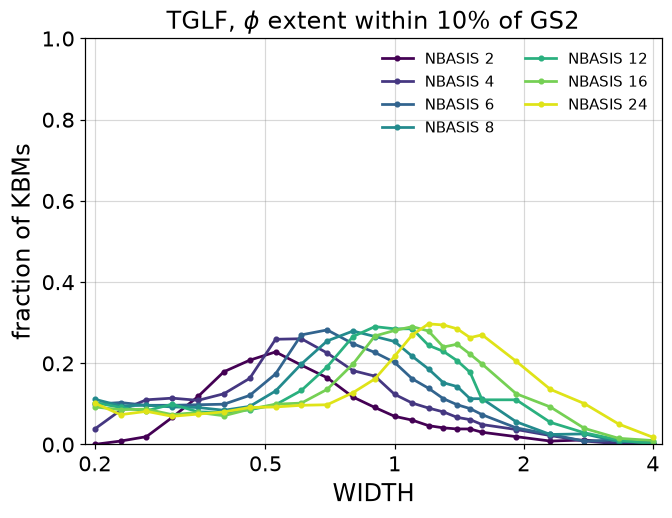

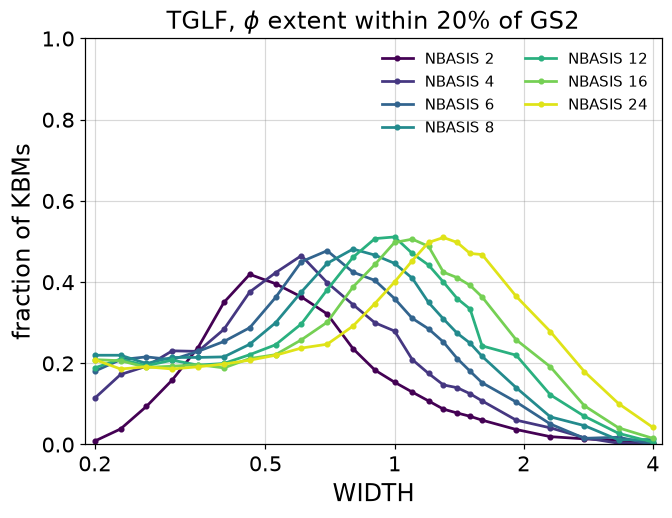

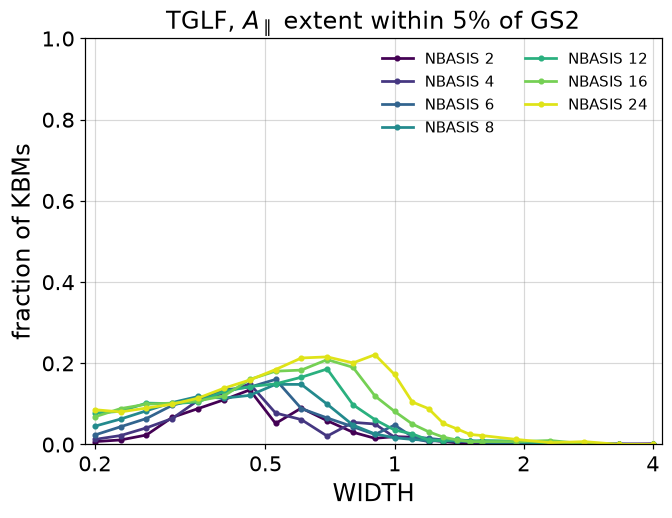

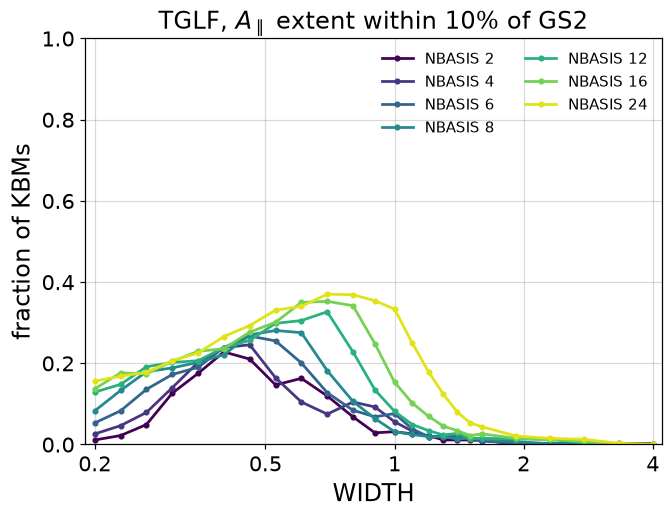

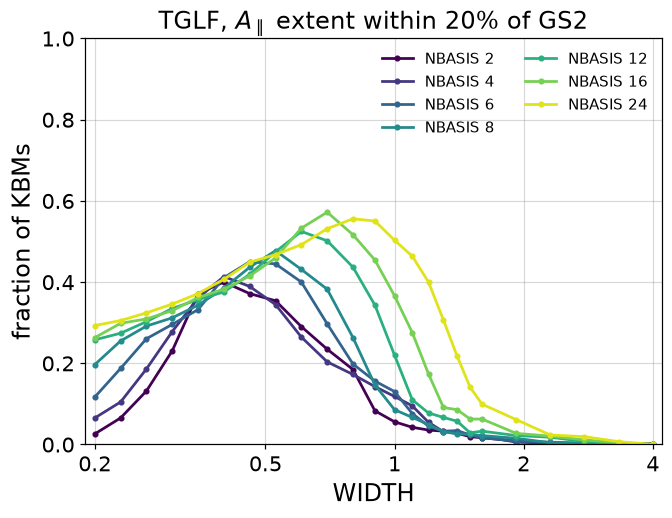

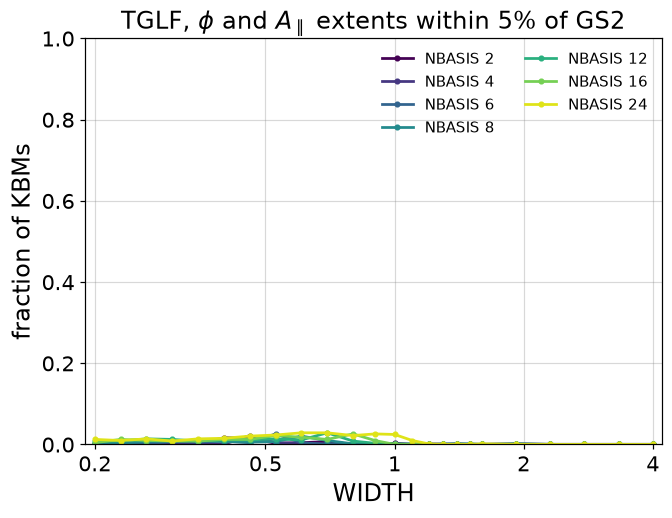

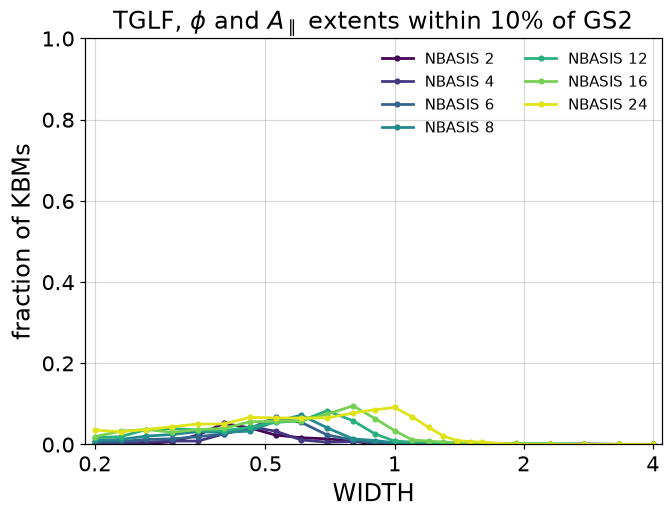

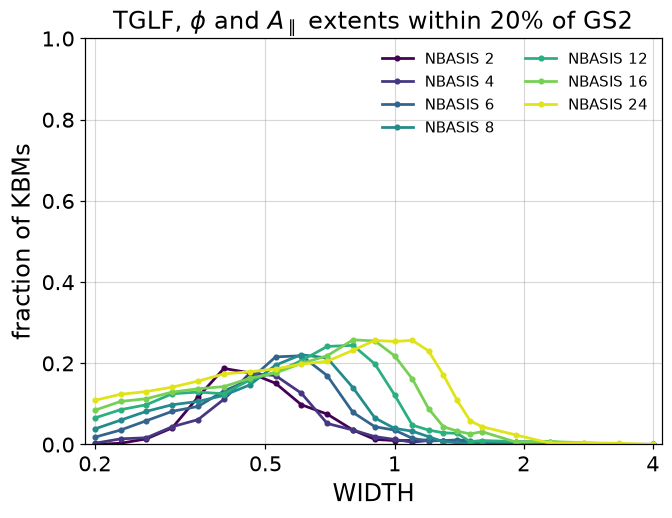

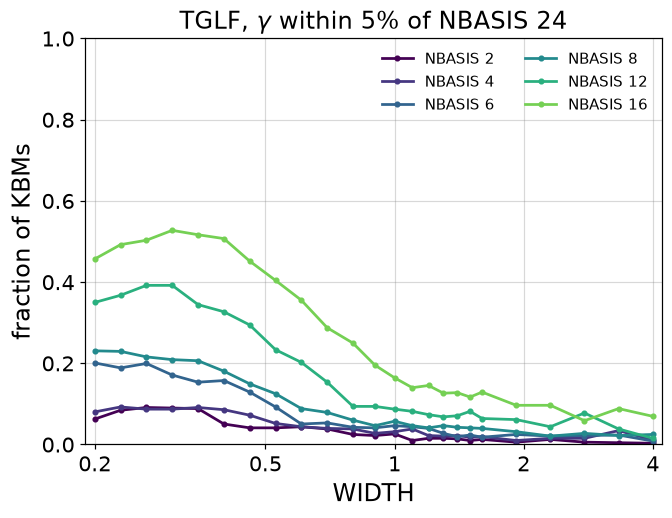

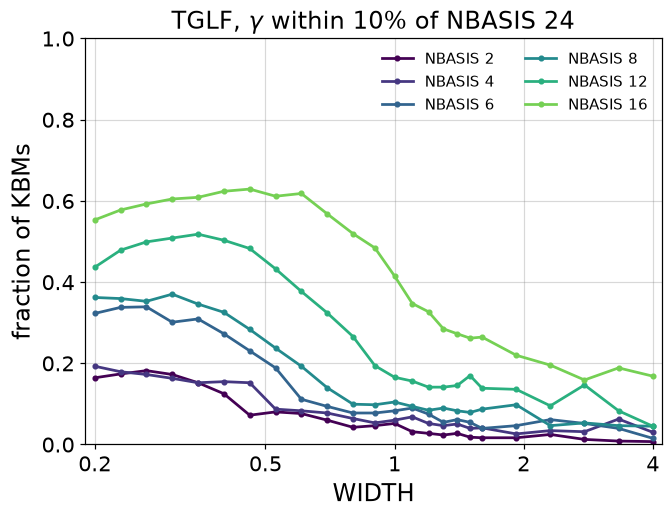

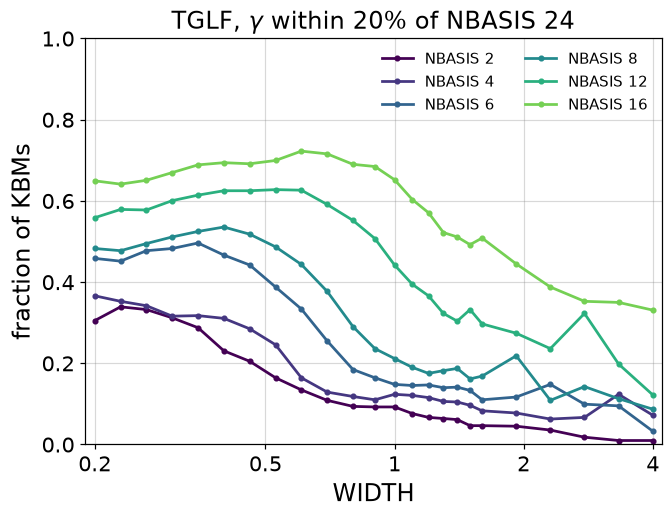

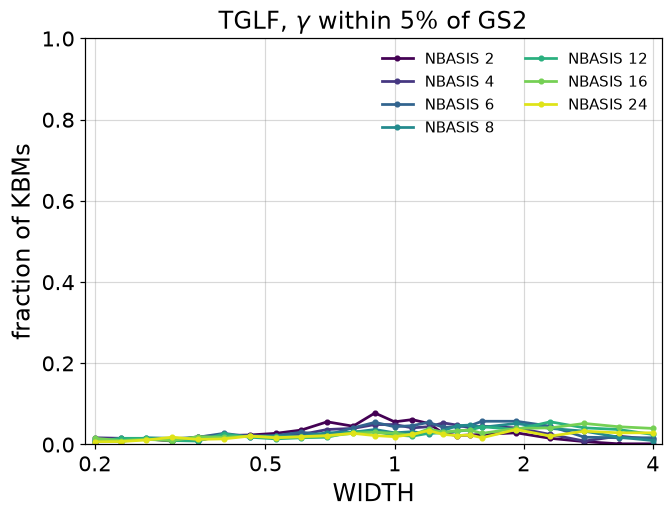

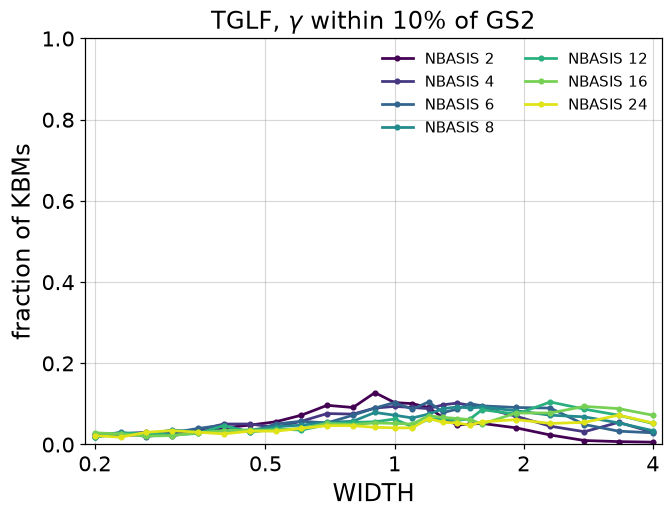

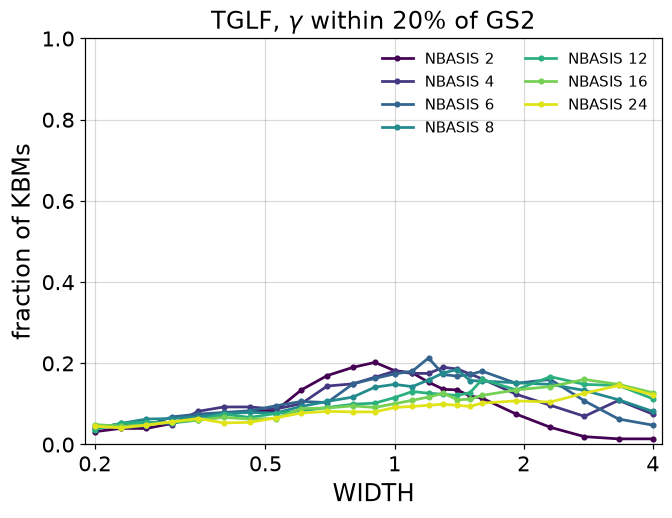

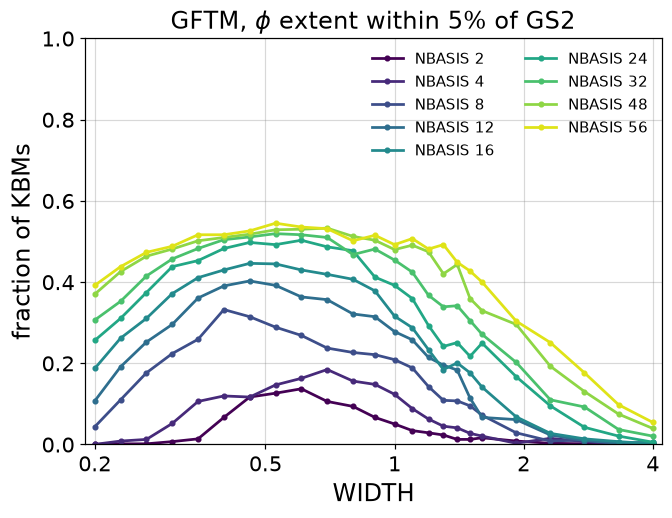

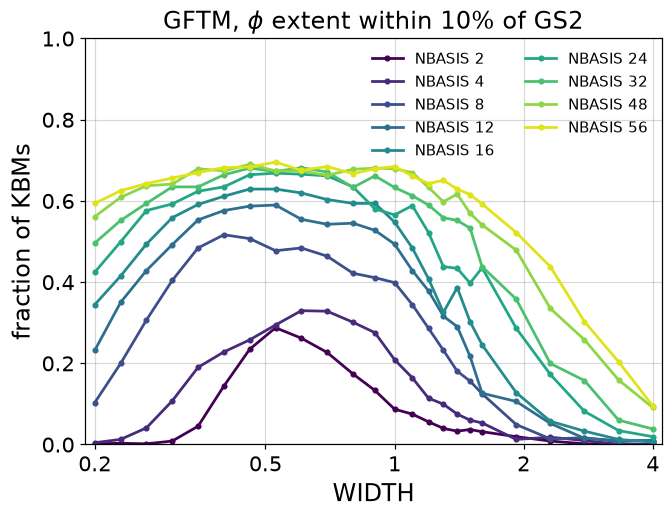

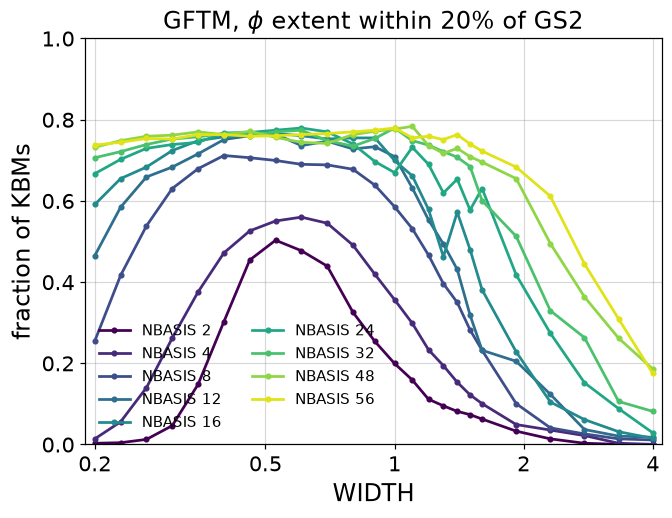

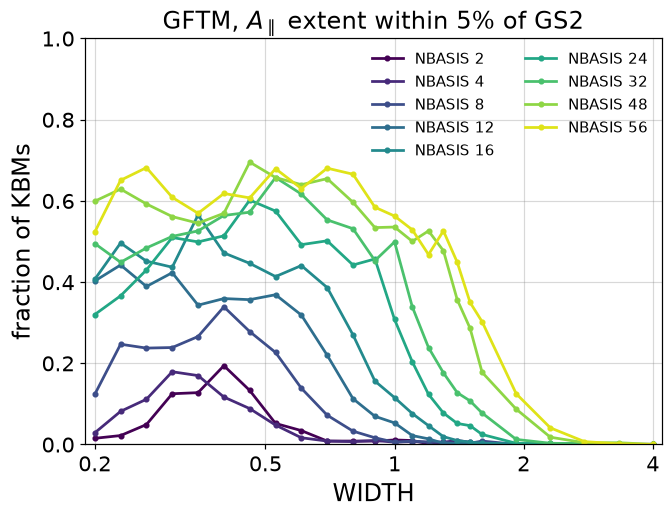

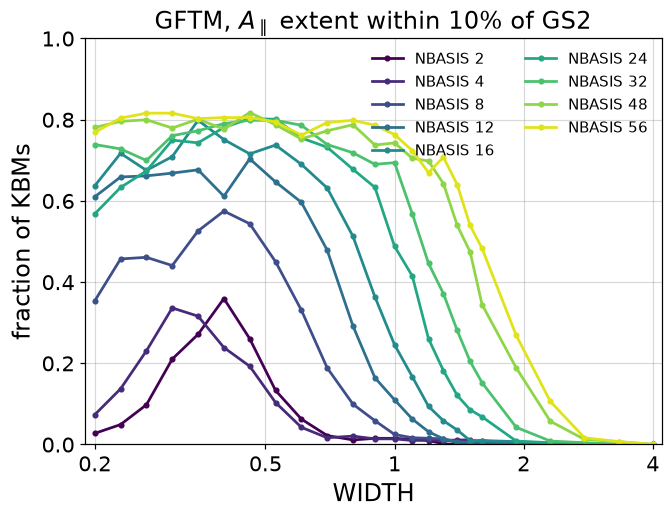

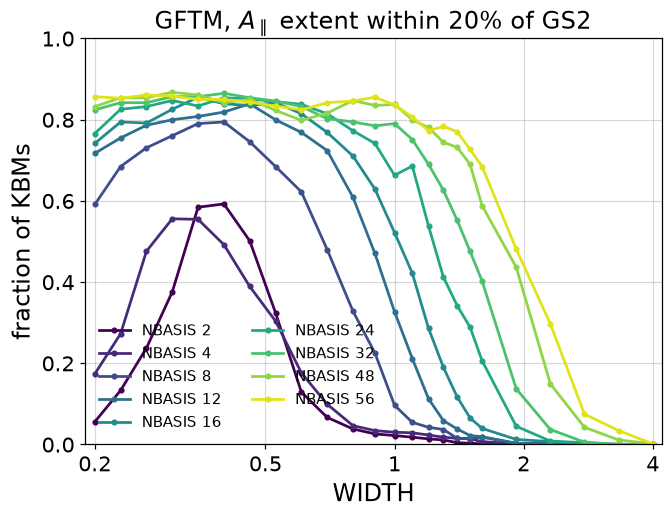

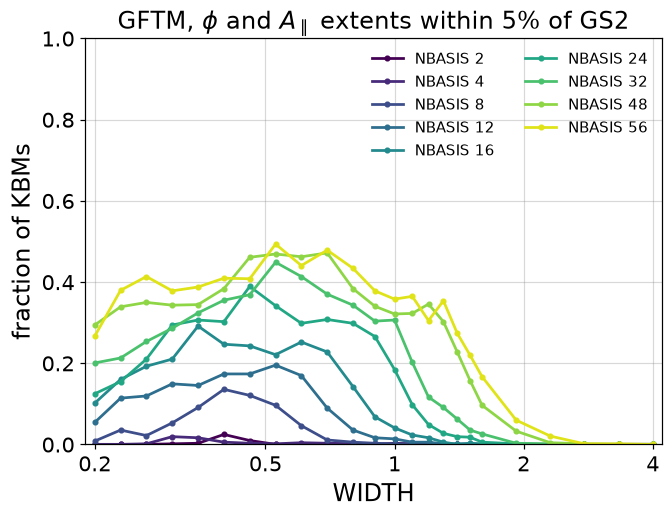

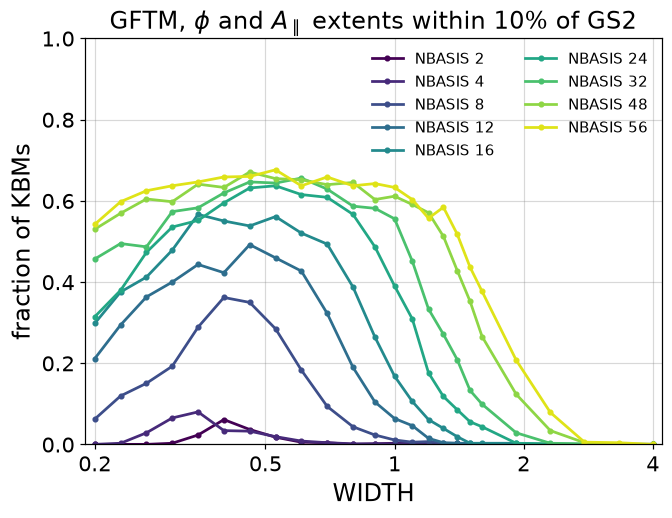

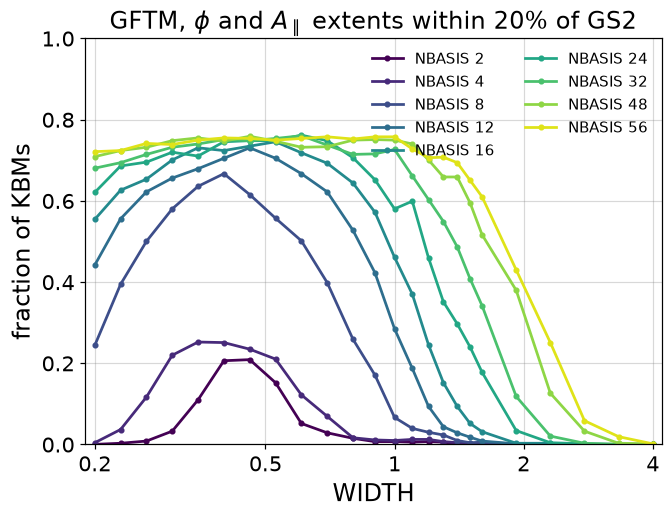

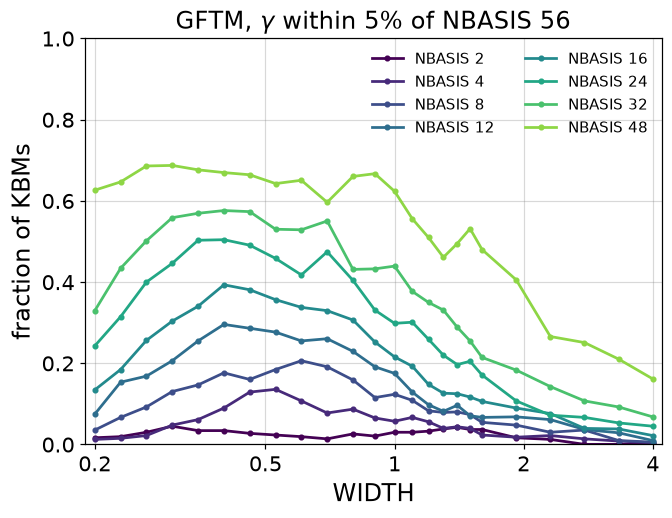

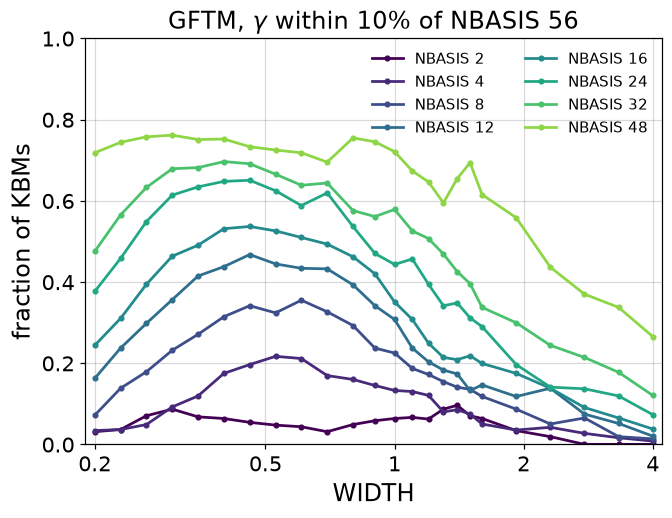

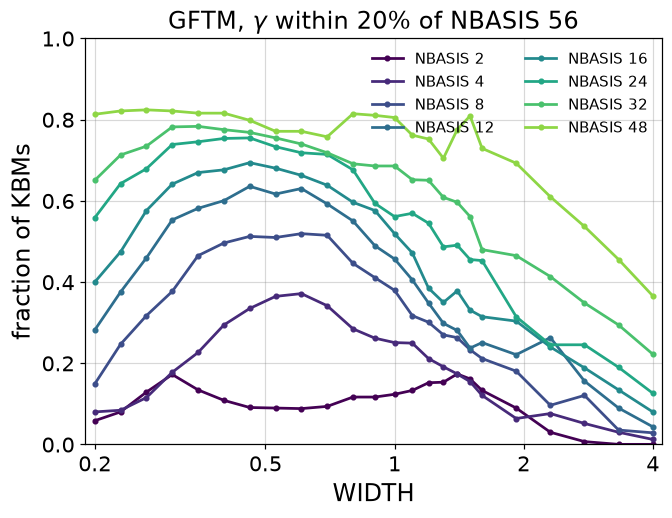

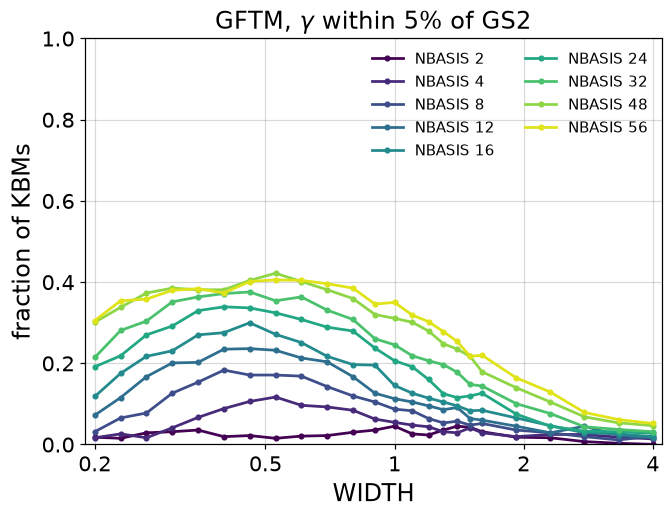

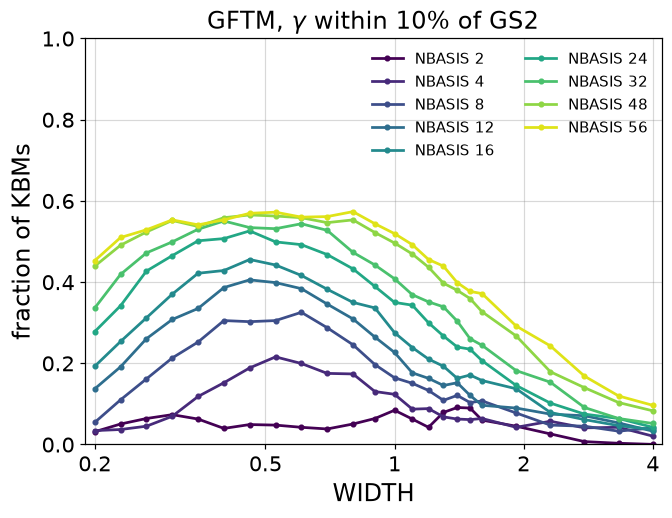

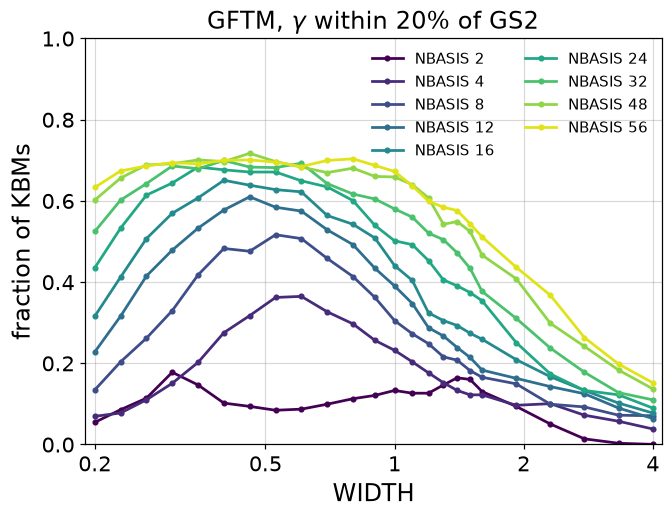

In [5]:
quantities = {"extent_phi": ("phi_extent_error", r"$\phi$ extent within {x:.0%} of GS2"),
              "extent_apar": ("apar_extent_error", r"$A_\parallel$ extent within {x:.0%} of GS2"),
              "extent": ("extent_error", r"$\phi$ and $A_\parallel$ extents within {x:.0%} of GS2"),
              "gamma": ("gamma_change", r"$\gamma$ within {x:.0%} of NBASIS {top}"),
              "gamma_gs2": ("gamma_error_gs2", r"$\gamma$ within {x:.0%} of GS2")}
for code in cells:
    data = runs[runs.code == code]
    ladder = [nbasis for nbasis, _ in cells[code]]
    colours = plt.cm.viridis(np.linspace(0, 0.95, len(ladder)))
    for quantity, (column, title) in quantities.items():
        for tolerance in tolerances:
            fig, ax = plt.subplots(figsize=(6, 4.6), constrained_layout=True)
            for nbasis, colour in zip(ladder, colours):
                if quantity == "gamma" and nbasis == top_nbasis[code]:
                    continue
                fraction = (data[data.nbasis == nbasis].groupby("width")[column].apply(lambda error: (error <= tolerance).mean()))
                ax.plot(fraction.index, fraction.values, color=colour, marker="o", ms=3, label=f"NBASIS {nbasis}")
            ax.set_xscale("log"); ax.set_xticks([0.2, 0.5, 1, 2, 4]); ax.set_xlim(0.19, 4.2); ax.set_ylim(0, 1)
            ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.xaxis.set_minor_locator(NullLocator())
            ax.set_title(f"{code}, " + title.format(x=tolerance, top=top_nbasis[code]), fontsize=16)
            ax.set_xlabel("WIDTH", fontsize=16); ax.set_ylabel("fraction of KBMs", fontsize=16); ax.tick_params(axis="both", labelsize=14)
            ax.legend(fontsize=10, ncol=2)
            stem = f"{code}_{quantity}_within_{round(100 * tolerance)}pct_fraction_vs_width_per_nbasis"
            fig.savefig(plots_dir / f"{stem}.pdf"); fig.savefig(plots_dir / f"{stem}.png", dpi=150)
            plt.show()